# 03 - Head training (frozen backbone)

**Goal:** train a map-sized MobileNetV3-Small head with the backbone frozen, using leak-safe splits from notebook 02.

This notebook:
- loads `class_map.json`, `env_report.json`, and a split manifest from `artifacts/`
- trains only the classifier head on DirectML
- supports **class-weighted loss** or **weighted sampling** for imbalance
- saves checkpoints and a training report for notebook 04

In [1]:
import json, random, time
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
import torch_directml

In [2]:
PROJECT_ROOT = Path.cwd().parent
ARTIFACTS = PROJECT_ROOT / "agrilens-training/artifacts"
ARTIFACTS.mkdir(exist_ok=True)

dml = torch_directml.device()
print("DirectML device:", torch_directml.device_name(0))
print("Torch version :", torch.__version__)


DirectML device: AMD Radeon RX 5700 
Torch version : 2.4.1+cpu


In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)


### Step 1 - load contracts and split manifest from notebook 02

In [4]:
class_map_path = ARTIFACTS / "class_map.json"
env_report_path = ARTIFACTS / "env_report.json"

assert class_map_path.exists(), f"Missing {class_map_path}; run notebook 01 first."
assert env_report_path.exists(), f"Missing {env_report_path}; run notebook 00 first."

class_map = json.loads(class_map_path.read_text(encoding="utf-8"))
env_report = json.loads(env_report_path.read_text(encoding="utf-8"))
labels = [c["label"] for c in sorted(class_map, key=lambda x: x["id"])]

preprocess = env_report["preprocess"]
INPUT_SIZE = int(preprocess["input_size"])
MEAN = preprocess["mean"]
STD = preprocess["std"]
NUM_CLASSES = len(labels)

candidates = [
    ARTIFACTS / "manifest_v2.csv",
    ARTIFACTS / "manifest_with_splits.csv",
    ARTIFACTS / "manifest_v2_splits.csv",
    ARTIFACTS / "splits_v1.csv",
]
split_path = next((p for p in candidates if p.exists()), None)
if split_path is None:
    raise FileNotFoundError(
        "No split manifest found. Run notebook 02 first and save one of: "
        + ", ".join(p.name for p in candidates)
    )

df = pd.read_csv(split_path)
print("using split manifest:", split_path)
print("rows:", len(df), "columns:", list(df.columns))


using split manifest: C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\manifest_v2.csv
rows: 11431 columns: ['path', 'file', 'class_id', 'label', 'sha1', 'bytes', 'w', 'h', 'mode', 'blur', 'brightness', 'group_v1', 'group_id', 'split', 'blur_flag']


In [5]:
required_cols = {"path", "class_id"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Split manifest is missing required columns: {missing}")

if "split" not in df.columns:
    bool_cols = ["is_train", "is_val", "is_test"]
    if all(c in df.columns for c in bool_cols):
        idx = df[bool_cols].astype(int).values.argmax(axis=1)
        name_map = np.array(["train", "val", "test"])
        df["split"] = name_map[idx]
    else:
        raise ValueError("Need either a 'split' column or boolean columns is_train/is_val/is_test.")

df["split"] = (
    df["split"]
    .astype(str)
    .str.strip()
    .str.lower()
    .replace({"valid": "val", "validation": "val"})
)

allowed = {"train", "val", "test"}
bad = sorted(set(df["split"]) - allowed)
if bad:
    raise ValueError(f"Unexpected split labels: {bad}. Expected only train/val/test.")

counts = df["split"].value_counts().to_dict()
for s in ["train", "val", "test"]:
    if counts.get(s, 0) == 0:
        raise ValueError(f"Split '{s}' has 0 rows. Check notebook 02 output.")

df = df.copy()
df["class_id"] = df["class_id"].astype(int)
if df["class_id"].min() < 0 or df["class_id"].max() >= NUM_CLASSES:
    raise ValueError("class_id values are outside [0, NUM_CLASSES).")

def resolve_path(p: str) -> Path:
    p0 = Path(str(p))
    if p0.exists():
        return p0
    p1 = PROJECT_ROOT / p0
    if p1.exists():
        return p1
    p2 = Path.cwd() / p0
    if p2.exists():
        return p2
    return p0

df["path_obj"] = df["path"].map(resolve_path)
missing_files = df.loc[~df["path_obj"].map(lambda p: p.exists()), "path"].head(10).tolist()
if missing_files:
    raise FileNotFoundError("Some image paths do not exist. Examples: " + " | ".join(missing_files))

print(df.groupby(["split", "class_id"]).size().unstack(fill_value=0))


class_id    0    1    2    3     4    5     6    7     8
split                                                   
test      179  148   77  174   319  150   286  143   238
train     834  689  359  814  1489  700  1336  666  1114
val       179  148   77  174   319  150   287  143   239


### Step 2 - datasets and dataloaders

In [6]:
train_tfms = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=12),
    transforms.ColorJitter(brightness=0.12, contrast=0.12, saturation=0.10, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((INPUT_SIZE, INPUT_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

class LeafDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, tfm):
        self.frame = frame.reset_index(drop=True)
        self.tfm = tfm

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(row.path_obj).convert("RGB")
        x = self.tfm(img)
        y = int(row.class_id)
        return x, y

train_df = df[df.split == "train"].copy()
val_df = df[df.split == "val"].copy()
test_df = df[df.split == "test"].copy()

print("train/val/test:", len(train_df), len(val_df), len(test_df))
print("train class counts:")
print(train_df["class_id"].value_counts().sort_index())


train/val/test: 8001 1716 1714
train class counts:
class_id
0     834
1     689
2     359
3     814
4    1489
5     700
6    1336
7     666
8    1114
Name: count, dtype: int64


### Step 3 - imbalance strategy (`class_weighted_loss` or `weighted_sampler`)

In [7]:
BATCH_SIZE = 32
NUM_WORKERS = 0
IMBALANCE_MODE = "class_weighted_loss"  # or "weighted_sampler"

train_counts = train_df["class_id"].value_counts().sort_index()
count_arr = np.array([train_counts.get(i, 0) for i in range(NUM_CLASSES)], dtype=np.float64)
if np.any(count_arr == 0):
    raise ValueError("At least one class has zero train examples after split.")

class_weights_np = count_arr.sum() / (NUM_CLASSES * count_arr)
class_weights_np = class_weights_np / class_weights_np.mean()
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=dml)

train_ds = LeafDataset(train_df, train_tfms)
val_ds = LeafDataset(val_df, eval_tfms)
test_ds = LeafDataset(test_df, eval_tfms)

if IMBALANCE_MODE == "weighted_sampler":
    sample_w = train_df["class_id"].map(lambda c: class_weights_np[int(c)]).astype(np.float64).to_numpy()
    sampler = WeightedRandomSampler(weights=sample_w, num_samples=len(sample_w), replacement=True)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
    loss_fn = nn.CrossEntropyLoss()
else:
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("imbalance mode:", IMBALANCE_MODE)
print("class weights:", np.round(class_weights_np, 3).tolist())


imbalance mode: class_weighted_loss
class weights: [0.906, 1.097, 2.105, 0.928, 0.507, 1.079, 0.566, 1.134, 0.678]


### Step 4 - model setup (freeze features, train classifier head)

In [8]:
weights = MobileNet_V3_Small_Weights.IMAGENET1K_V1
model = mobilenet_v3_small(weights=weights)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, NUM_CLASSES)

for p in model.features.parameters():
    p.requires_grad = False

model = model.to(dml)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"trainable params: {trainable:,} / {total:,}")

LR = 1e-3
WEIGHT_DECAY = 1e-4
optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=18)


trainable params: 600,073 / 1,527,081


### Step 5 - train and validate

In [9]:
EPOCHS = 18
PATIENCE = 4
best_val_loss = float("inf")
best_epoch = -1
patience_left = PATIENCE
history = []

best_ckpt = ARTIFACTS / "mobilenetv3_head_best.pt"
last_ckpt = ARTIFACTS / "mobilenetv3_head_last.pt"

@torch.no_grad()
def evaluate(loader):
    model.eval()
    n, correct, loss_sum = 0, 0, 0.0
    for xb, yb in loader:
        xb = xb.to(dml)
        yb = yb.to(dml)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        bs = yb.shape[0]
        loss_sum += float(loss.item()) * bs
        correct += int((logits.argmax(1) == yb).sum().item())
        n += bs
    return {"loss": loss_sum / max(n, 1), "acc": correct / max(n, 1)}

for epoch in range(1, EPOCHS + 1):
    t0 = time.perf_counter()
    model.train()
    tr_n, tr_correct, tr_loss_sum = 0, 0, 0.0

    for xb, yb in train_loader:
        xb = xb.to(dml)
        yb = yb.to(dml)

        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

        bs = yb.shape[0]
        tr_loss_sum += float(loss.item()) * bs
        tr_correct += int((logits.argmax(1) == yb).sum().item())
        tr_n += bs

    scheduler.step()
    train_loss = tr_loss_sum / max(tr_n, 1)
    train_acc = tr_correct / max(tr_n, 1)
    val_m = evaluate(val_loader)
    dt = time.perf_counter() - t0

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_m["loss"],
        "val_acc": val_m["acc"],
        "epoch_s": dt,
        "lr": float(optimizer.param_groups[0]["lr"]),
    }
    history.append(row)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in row.items()})

    torch.save({
        "epoch": epoch,
        "state_dict": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "history": history,
    }, last_ckpt)

    if val_m["loss"] + 1e-8 < best_val_loss:
        best_val_loss = val_m["loss"]
        best_epoch = epoch
        patience_left = PATIENCE
        torch.save({
            "epoch": epoch,
            "state_dict": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "history": history,
            "imbalance_mode": IMBALANCE_MODE,
            "class_weights": class_weights_np.tolist(),
        }, best_ckpt)
    else:
        patience_left -= 1
        if patience_left <= 0:
            print("Early stopping triggered.")
            break

print("best epoch:", best_epoch, "best val loss:", round(best_val_loss, 5))


C:\Users\baabyface\documents\my work\agrilens\agrilens-training\.venv\Lib\site-packages\torch\optim\adamw.py:529: UserWarning: The operator 'aten::lerp.Scalar_out' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  torch._foreach_lerp_(device_exp_avgs, device_grads, 1 - beta1)


{'epoch': 1, 'train_loss': 0.4293, 'train_acc': 0.8605, 'val_loss': 0.1683, 'val_acc': 0.9376, 'epoch_s': 86.3551, 'lr': 0.001}
{'epoch': 2, 'train_loss': 0.2513, 'train_acc': 0.914, 'val_loss': 0.1448, 'val_acc': 0.9458, 'epoch_s': 82.5679, 'lr': 0.001}
{'epoch': 3, 'train_loss': 0.206, 'train_acc': 0.9339, 'val_loss': 0.1741, 'val_acc': 0.9307, 'epoch_s': 81.3661, 'lr': 0.0009}
{'epoch': 4, 'train_loss': 0.183, 'train_acc': 0.9409, 'val_loss': 0.1241, 'val_acc': 0.9522, 'epoch_s': 74.3868, 'lr': 0.0009}
{'epoch': 5, 'train_loss': 0.162, 'train_acc': 0.9433, 'val_loss': 0.1312, 'val_acc': 0.951, 'epoch_s': 73.4988, 'lr': 0.0008}
{'epoch': 6, 'train_loss': 0.1518, 'train_acc': 0.9486, 'val_loss': 0.1204, 'val_acc': 0.9505, 'epoch_s': 76.1744, 'lr': 0.0007}
{'epoch': 7, 'train_loss': 0.128, 'train_acc': 0.957, 'val_loss': 0.0837, 'val_acc': 0.9691, 'epoch_s': 72.4941, 'lr': 0.0007}
{'epoch': 8, 'train_loss': 0.1171, 'train_acc': 0.9629, 'val_loss': 0.086, 'val_acc': 0.9691, 'epoch_s': 8

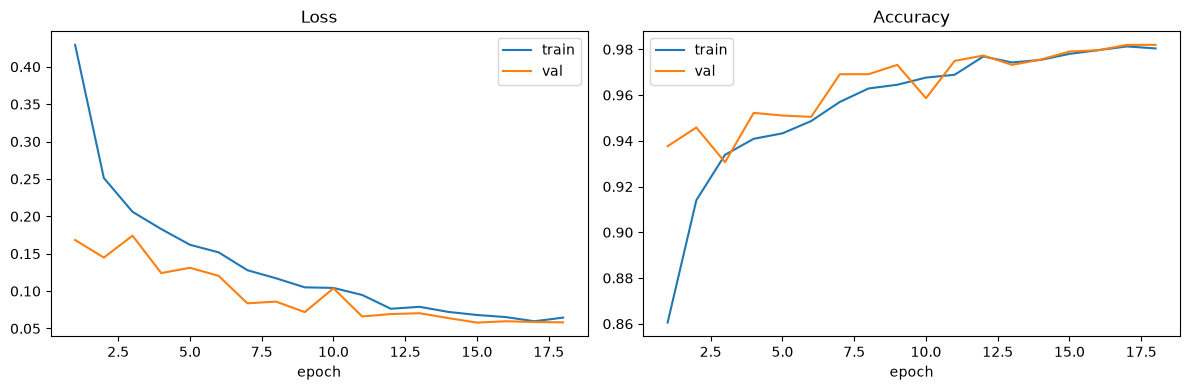

In [10]:
hist = pd.DataFrame(history)
if hist.empty:
    raise RuntimeError("Training did not run; history is empty.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train")
ax[0].plot(hist["epoch"], hist["val_loss"], label="val")
ax[0].set_title("Loss")
ax[0].set_xlabel("epoch")
ax[0].legend()

ax[1].plot(hist["epoch"], hist["train_acc"], label="train")
ax[1].plot(hist["epoch"], hist["val_acc"], label="val")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("epoch")
ax[1].legend()
plt.tight_layout()
plt.show()


### Step 6 - evaluate best checkpoint on test split and save report

In [11]:
best = torch.load(best_ckpt, map_location="cpu")
model.load_state_dict(best["state_dict"])
model = model.to(dml)

val_final = evaluate(val_loader)
test_final = evaluate(test_loader)
print("val:", {k: round(v, 4) for k, v in val_final.items()})
print("test:", {k: round(v, 4) for k, v in test_final.items()})

hist_path = ARTIFACTS / "head_training_history.csv"
hist.to_csv(hist_path, index=False)

report = {
    "split_manifest": str(split_path),
    "num_classes": NUM_CLASSES,
    "labels": labels,
    "imbalance_mode": IMBALANCE_MODE,
    "class_weights": class_weights_np.tolist(),
    "train_size": int(len(train_df)),
    "val_size": int(len(val_df)),
    "test_size": int(len(test_df)),
    "best_epoch": int(best["epoch"]),
    "best_val_loss": float(best_val_loss),
    "final_val": {k: float(v) for k, v in val_final.items()},
    "final_test": {k: float(v) for k, v in test_final.items()},
    "checkpoints": {
        "best": str(best_ckpt),
        "last": str(last_ckpt)
    },
}

(ARTIFACTS / "head_training_report.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
print("saved", hist_path)
print("saved", ARTIFACTS / "head_training_report.json")


C:\Users\baabyface\AppData\Local\Temp\ipykernel_648\896064553.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  best = torch.load(best_ckpt, map_location="cpu")


val: {'loss': 0.0579, 'acc': 0.979}
test: {'loss': 0.0604, 'acc': 0.9737}
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\head_training_history.csv
saved C:\Users\baabyface\Documents\my work\agrilens\agrilens-training\artifacts\head_training_report.json
